# Data Processing & Modeling

In this step, the data will be processed to train a semantic segmentation model and evaluate its performance.

## Imports

In [16]:
# Images
import os
import seaborn as sns
import pandas as pd
import numpy as np
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.colors import ListedColormap

# Modeling
from ultralytics import YOLO

## Data Processing 

YOLO uses a `dataset.yaml` file to define the dataset paths and expects a specific directory structure.

The current structure is:
```bash
data/raw/ 
├── train/ 
│ ├── train_images/ 
│ └── train_masks/ 
├── valid/ 
│ ├── valid_images/ 
│ └── valid_masks/ 
└── test/ 
  ├── test_images/ 
  └── test_masks/
```
Therefore, we will reorganize the dataset into the following structure:
```bash
data/processed/ 
├── images/ 
│ ├── train/ 
│ ├── valid/ 
│ └── test/ 
└── masks/ 
  ├── train/ 
  ├── valid/ 
  └── test/
```

The `dataset.yaml` file will define the dataset paths and class names:
```yaml
path: ../bubbles/data/processed
train: images/train
val: images/valid
test: images/test

masks_dir: masks

names:
  0: background
  1: bubble
```

### Mask Preprocessing
According to the [Semantic Segmentation with Ultralytics YOLO documentation](https://docs.ultralytics.com/tasks/semantic#:~:text=Pixels%20with%20value%20255%20are%20treated%20as%20%22ignore%22%20and%20excluded%20from%20loss%20computation.) pixels with a value of `255` are treated as ignore and excluded from loss computation.

The masks currently use pixel values of `0` and `255`. To represent the two classes cosistently, we will convert the masks to binary values: `0` for background and `1` for bubbles.

In [2]:
for split in ["train", "valid", "test"]:
    source_dir = Path("../../data/raw") / split / f"{split}_masks"
    target_dir = Path("../../data/processed/masks") / split
    target_dir.mkdir(parents=True, exist_ok=True)

    for path in source_dir.glob("*.png"):
        mask = np.array(Image.open(path).convert("L"))
        # Convert mask pixel values to binary (0 or 1)
        mask = (mask > 127).astype(np.uint8)
        Image.fromarray(mask).save(target_dir / path.name)

    print(f"{split}: {len(list(target_dir.glob('*.png')))} masks saved")

train: 13613 masks saved
valid: 2546 masks saved
test: 3631 masks saved


## Model Training

The `YOLO26n-sem` model will be used, it is the smallest model in terms of parameter count and is designed for fast inference, making it a suitable candidate for fast training and inference.

Initially, the model will be trained on 10% of the approximately 13.000 training images for 5 epochs.

The results will be saved in `../../runs/semantic/experiment_01` and the best model weights will be saved in `../../runs/semantic/experiment_01/weights/best.pt`.

In [3]:
# Load model
model = YOLO("yolo26n-sem.pt")

# Train model
results = model.train(
    data="../../dataset.yaml",
    epochs=5,
    imgsz=640,
    batch=4,
    fraction=0.1,
    seed=42,
    name="experiment_01"
)

New https://pypi.org/project/ultralytics/8.4.175 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.174 🚀 Python-3.11.16 torch-2.14.1+cu130 CPU (Intel Core i5-1035G1 1.00GHz)


/home/olver/bubbles/.venv/lib/python3.11/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=../../dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.1, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-sem.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=experiment_01, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12.0, pre

/home/olver/bubbles/.venv/lib/python3.11/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


YOLO26n-sem summary (fused): 73 layers, 1,625,612 parameters, 0 gradients, 4.4 GFLOPs
                 Class     Images     Pixels       mIoU     PixAcc: 100% ━━━━━━━━━━━━ 637/637 3.0it/s 3:300.3ss
                   all       2546  782131000      0.665       0.89
            background       2546  676494656      0.879      0.923
                bubble       2546  105636344      0.452      0.673
Speed: 1.0ms preprocess, 38.9ms inference, 0.0ms loss, 3.4ms postprocess per image
Results saved to /home/olver/bubbles/runs/semantic/experiment_01


## Evaluation

The model will be evaluated using the best weights obtained during training and the validation set.

Some metrics are not saved as expected, so we use the previously collected `metrics` to save the remaining metrics or calculate new ones.

The results will be saved in `../../runs/semantic/val`.

In [3]:
model = YOLO("../../runs/semantic/experiment_01/weights/best.pt")
metrics = model.val()
def save_confusion_matrix():
    cm = metrics.confusion_matrix.matrix
    cm_normalized = cm / (cm.sum(axis=0, keepdims=True) + 1e-9)
    df_cm = pd.DataFrame(cm)
    df_cm_normalized = pd.DataFrame(cm_normalized)
    df_cm.to_csv("../../metrics/confusion_matrix.csv", index=False)
    df_cm_normalized.to_csv("../../metrics/confusion_matrix_normalized.csv", index=False)
def save_precision_recall():
    df_cm = pd.read_csv("../../metrics/confusion_matrix.csv")
    df_cm.columns = df_cm.columns.astype(int)
    TP = df_cm.loc[1,1]
    TN = df_cm.loc[0,0]
    FP = df_cm.loc[1,0]
    FN = df_cm.loc[0,1]
    bubble_precision = TP / (TP + FP)
    bubble_recall = TP / (TP + FN)
    background_precision = TN / (TN + FN)
    background_recall = TN / (TN + FP)
    precision_recall = pd.DataFrame(
        columns = ["class", "Precision", "Recall"],
        data = [
            ["background", background_precision, background_recall],
            ["bubble", bubble_precision, bubble_recall]
        ]
    )
    precision_recall.to_csv("../../metrics/precision_recall.csv", index=False)
def save_iou_pix_acc():
    iou_pix_acc = pd.DataFrame(
    columns=["class", "mIoU", "Pixel Accuracy"], 
    data= [
        ["all", metrics.miou, metrics.pixel_accuracy],
        ["background", metrics.per_class_iou[0], metrics.per_class_pixel_accuracy[0]],
        ["bubble", metrics.per_class_iou[1], metrics.per_class_pixel_accuracy[1]],
    ])
    iou_pix_acc.to_csv("../../metrics/iou_pix_acc.csv", index=False)
def save_dice_similarity_coefficient():
    df_iou_pix_acc = pd.read_csv("../../metrics/iou_pix_acc.csv")
    background_mIoU = df_iou_pix_acc.loc[1, "mIoU"]
    bubble_mIoU = df_iou_pix_acc.loc[2, "mIoU"]
    background_dsc = (2 * background_mIoU) / (1 + background_mIoU)
    bubble_dsc = (2 * bubble_mIoU) / (1 + bubble_mIoU)
    
    dsc = pd.DataFrame(
        columns = ["class", "Dice Similarity Coefficient"],
        data = [
            ["background", background_dsc],
            ["bubble", bubble_dsc]
        ]
    )
    dsc.to_csv("../../metrics/dsc.csv", index=False)
save_confusion_matrix()
save_precision_recall()
save_iou_pix_acc()
save_dice_similarity_coefficient()

Ultralytics 8.4.174 🚀 Python-3.11.16 torch-2.14.1+cu130 CPU (Intel Core i5-1035G1 1.00GHz)
YOLO26n-sem summary (fused): 73 layers, 1,625,612 parameters, 0 gradients, 4.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1406.1±1663.8 MB/s, size: 669.5 KB)
val: Scanning /home/olver/bubbles/data/processed/masks/valid.cache... 2546 images, 0 missing masks, 0 corrupt: 100% ━━━━━━━━━━━━ 2546/2546 667.4Mit/s 0.0s


/home/olver/bubbles/.venv/lib/python3.11/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


                 Class     Images     Pixels       mIoU     PixAcc: 100% ━━━━━━━━━━━━ 160/160 1.3s/it 3:341.9ss
                   all       2546  782131072      0.665       0.89
            background       2546  676494720      0.879      0.923
                bubble       2546  105636352      0.452      0.673
Speed: 1.5ms preprocess, 34.1ms inference, 0.0ms loss, 3.4ms postprocess per image
Results saved to /home/olver/bubbles/runs/semantic/val


### Confusion Matrix
The confusion matrix reveals a class imbalance, as most pixels belong to the background class, while only a smaller proportion corresponds to bubbles. The model produces 51.752.584 false positives, indicating difficulties in distinguishing bubbles from the background pixels.

The normalized confusion matrix shows that the model correctly identifies approximately 67% of the actual bubble pixels.

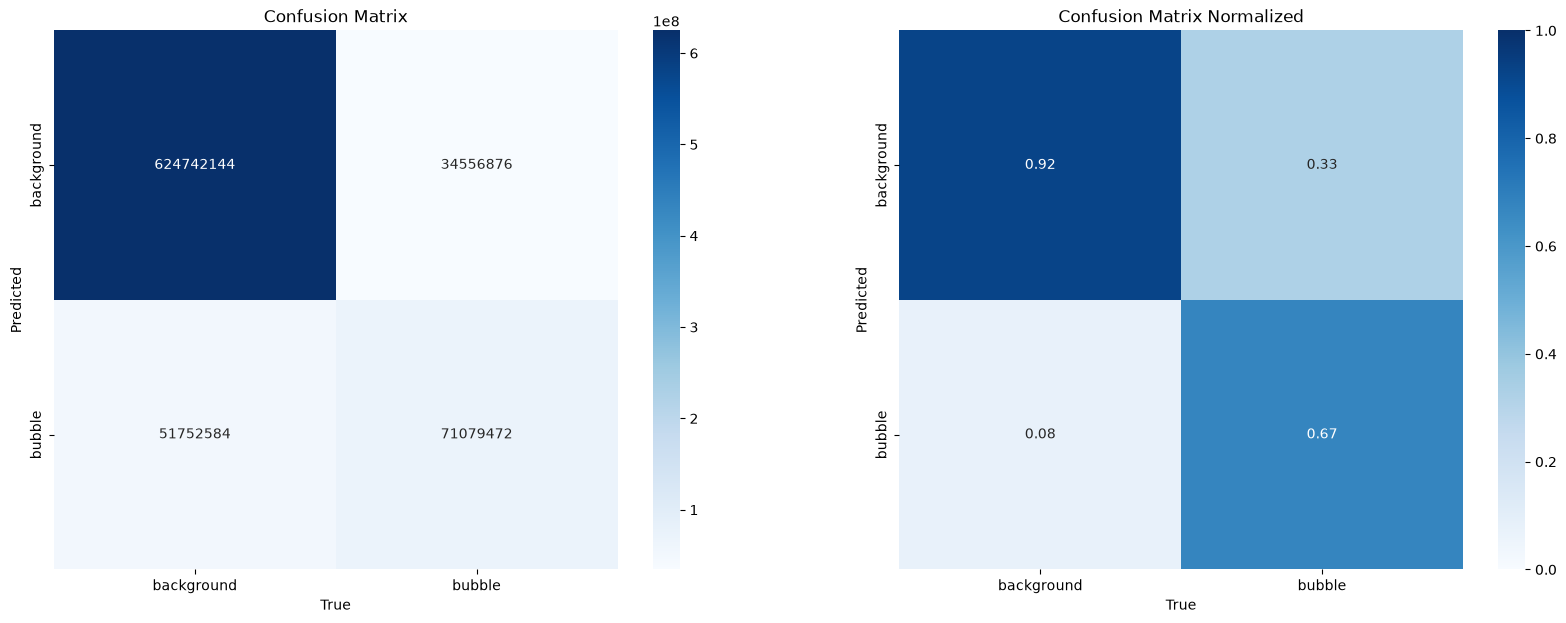

In [7]:
df_cm = pd.read_csv("../../metrics/confusion_matrix.csv")
df_cm_normalized = pd.read_csv("../../metrics/confusion_matrix_normalized.csv")

labels = ["background", "bubble"]

fig, (ax1, ax2) = plt.subplots( 1, 2, figsize=(20,7))
sns.heatmap(
    df_cm,
    ax=ax1,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
ax1.set_title("Confusion Matrix")
ax1.set_xlabel("True")
ax1.set_ylabel("Predicted")
sns.heatmap(
    df_cm_normalized,
    ax=ax2,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=labels,
    yticklabels=labels
)
ax2.set_title("Confusion Matrix Normalized")
ax2.set_xlabel("True")
ax2.set_ylabel("Predicted")
plt.show()

### Precision and  Recall 
The bubble class requires improvements in both precision and recall. The model tends to predict bubbles where there are none, with a precision of 0.57, while correctly identifying 67% of the actual bubble pixels, corresponding to a recall of 0.67

In [3]:
precision_recall = pd.read_csv("../../metrics/precision_recall.csv")
print(precision_recall)

        class  Precision    Recall
0  background   0.947585  0.923499
1      bubble   0.578672  0.672869


### mIoU and Pixel Accuracy
For the bubble class, the Intersection over Union is 0.45, indicating a limited overlap between the predicted and ground truth masks. The model still struggles to accurately delineate the bubbles.

Pixel Accuracy values match the Recall values reported previously. They provide no additional information in this evaluation.

In [4]:
iou_pix_acc = pd.read_csv("../../metrics/iou_pix_acc.csv")
print(iou_pix_acc)

        class      mIoU  Pixel Accuracy
0         all  0.665117        0.889648
1  background  0.878617        0.923499
2      bubble  0.451617        0.672869


### Dice Similarity Coefficient
The Dice Similarity Coefficient shows similar limitations to those observed with IoU.

In [8]:
dsc = pd.read_csv("../../metrics/dsc.csv")
print(dsc)

        class  Dice Similarity Coefficient
0  background                     0.935387
1      bubble                     0.622226


### Metrics vs Epoch
Cross-Entropy Loss decreases similarly for both the training and validation sets.

Dice Loss shows a slight gap between the training and validation curves, suggesting a possible tendency toward overfitting.

Mean IoU and Pixel Accuracy incresase rapidly and begin to plateau in the final epochs.

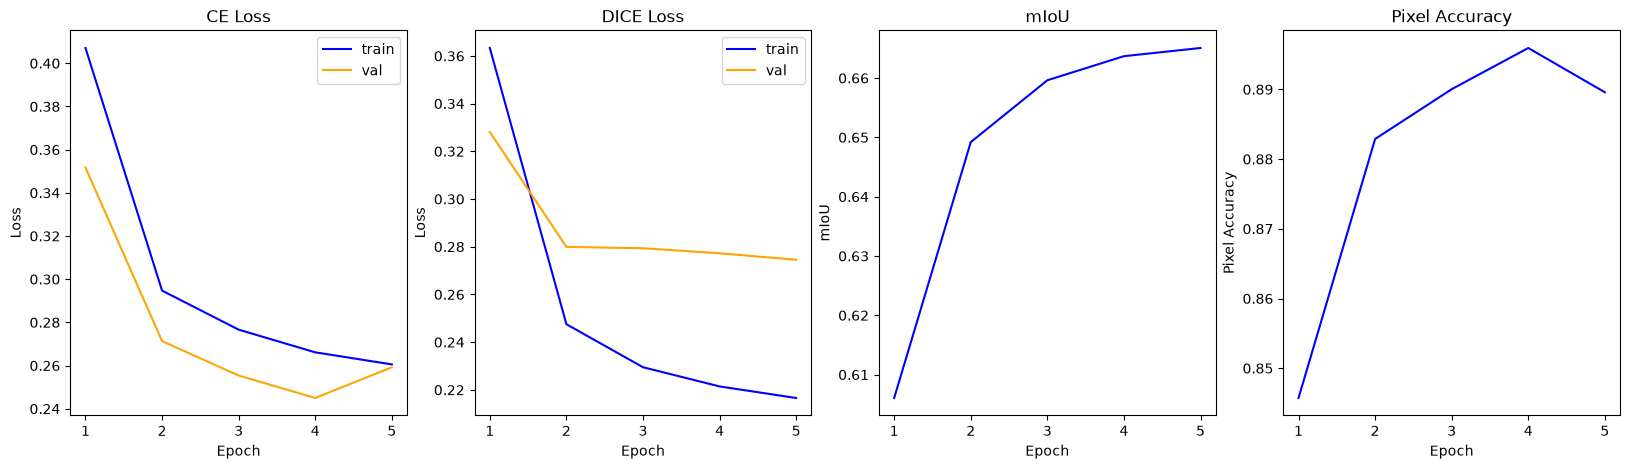

In [9]:
results_df = pd.read_csv("../../runs/semantic/experiment_01/results.csv")
fig, ((ax1, ax2, ax3, ax4)) = plt.subplots(1, 4, figsize=(20, 5))

ax1.plot(results_df["epoch"], results_df["train/ce_loss"], color="blue", label="train")
ax1.plot(results_df["epoch"], results_df["val/ce_loss"], color="orange", label="val")
ax1.set_title("CE Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()

ax2.plot(results_df["epoch"], results_df["train/dice_loss"], color="blue", label="train")
ax2.plot(results_df["epoch"], results_df["val/dice_loss"], color="orange", label="val")
ax2.set_title("DICE Loss")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss")
ax2.legend()

ax3.plot(results_df["epoch"], results_df["metrics/mIoU"], color="blue")
ax3.set_title("mIoU")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("mIoU")

ax4.plot(results_df["epoch"], results_df["metrics/pixel_acc"], color="blue")
ax4.set_title("Pixel Accuracy")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Pixel Accuracy")

for ax in [ax1, ax2, ax3, ax4]:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

## Predictions

Five images will be randomly selected to compare the original images, ground-truth masks, and predicted masks generated by the previously trained model.

It can be observed that the ground-truth masks tend to label bubbles outside the froth surface, which could be considered annotation noise.

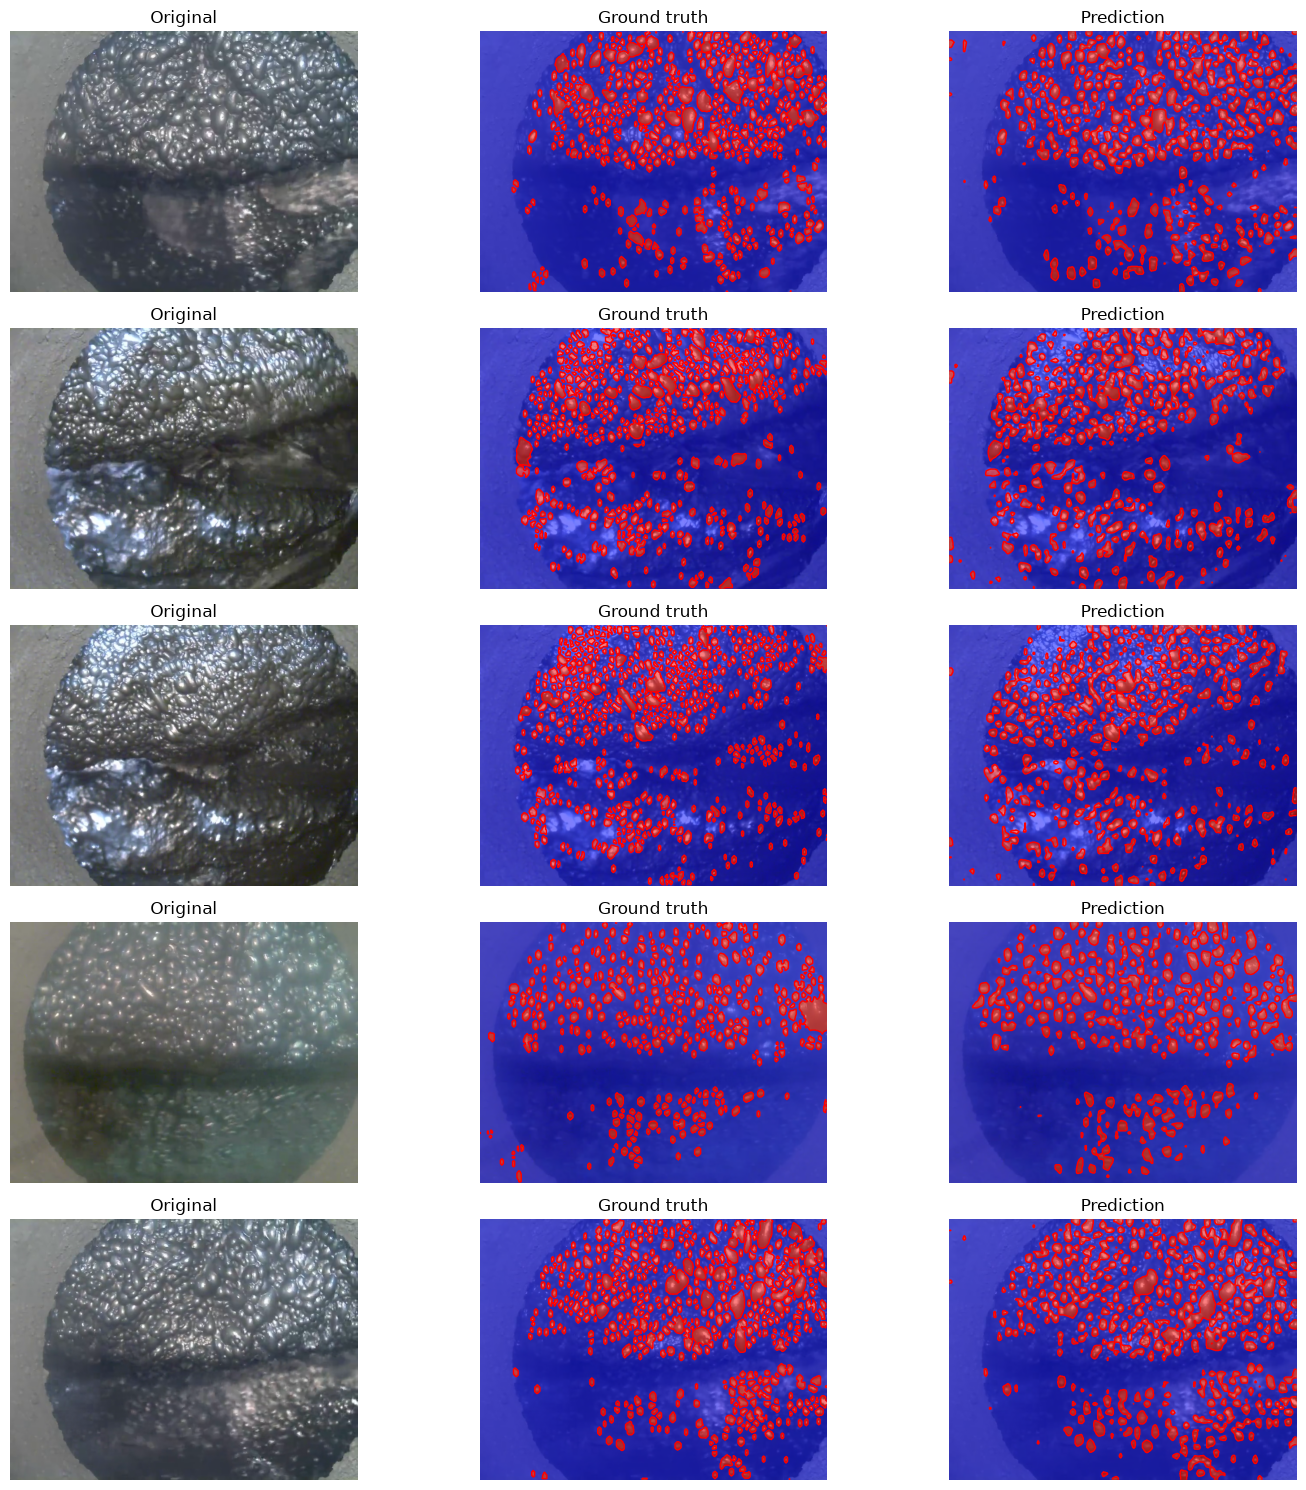

In [42]:
np.random.seed(42)
model = YOLO("../../runs/semantic/experiment_01/weights/best.pt")

names = np.random.choice([f for f in os.listdir("../../data/processed/images/valid") if f.endswith(".png")], size=5, replace=False)
images = [np.array(Image.open(Path("../../data/processed/images/valid") / name)) for name in names]
masks = [np.array(Image.open(Path("../../data/processed/masks/valid") / name)) for name in names]

results = model.predict(source=images, imgsz=640, verbose=False)
preds = [result.semantic_mask.data.cpu().numpy() for result in results]

fig, axes = plt.subplots(5, 3, figsize=(15, 15))
cmap = ListedColormap(["blue", "red"])

for i in range(5):
    axes[i, 0].imshow(images[i])
    axes[i, 0].set_title("Original")
    axes[i, 0].axis("off")
    
    axes[i, 1].imshow(images[i])
    axes[i, 1].imshow(masks[i], alpha=0.5, cmap="bwr")
    axes[i, 1].contour(masks[i], levels=[0.5], colors=["red"], linewidths=1)
    axes[i, 1].set_title("Ground truth")
    axes[i, 1].axis("off")
    
    axes[i, 2].imshow(images[i])
    axes[i, 2].imshow(preds[i], alpha=0.5, cmap="bwr")
    axes[i, 2].contour(preds[i], levels=[0.5], colors=["red"], linewidths=1)
    axes[i, 2].set_title("Prediction")
    axes[i, 2].axis("off")
plt.tight_layout()
plt.show()

## Experiment on Cloud

## Final Evaluation